In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.cluster import DBSCAN
import pdb

COLOR_ZPDES = "#114B5B"
COLOR_BASELINE = "#9CC19F"

In [2]:
def parse_trajectory(row):
    values = row['trajectory'][1:-1].split()
    values = np.array(list(map(lambda x: float(x), values)))
    return values

In [3]:
v3_prolific_binary = pd.read_csv("../outputs/v3_prolific/v3_prolific_binary_intra.csv")
v3_prolific_continuous = pd.read_csv("../outputs/v3_prolific/v3_prolific_F1_intra.csv")
v3_utl_binary = pd.read_csv("../outputs/v3_utl/v3_utl_binary_intra.csv")
v3_utl_continuous = pd.read_csv("../outputs/v3_utl/v3_utl_F1_intra.csv")
v3_prolific_binary['trajectory'] = v3_prolific_binary.apply(parse_trajectory, axis=1)
v3_prolific_continuous['trajectory'] = v3_prolific_continuous.apply(parse_trajectory, axis=1)
v3_utl_binary['trajectory'] = v3_utl_binary.apply(parse_trajectory, axis=1)
v3_utl_continuous['trajectory'] = v3_utl_continuous.apply(parse_trajectory, axis=1)

In [12]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

def get_2way_anova(df, name):
    print(name)
    df_melted = df.melt(id_vars=["participant_id", "condition"], 
                        value_vars=["s_0", "s_1", "s_2", "s_3"],
                        var_name="time",
                        value_name="value")
    model = ols('value ~ C(condition) + C(time) + C(condition):C(time)', data=df_melted).fit()
    anova_results = sm.stats.anova_lm(model, typ=2)
    print(anova_results)
    print('\n')
get_2way_anova(v3_prolific_binary, "v3_prolific_binary")
get_2way_anova(v3_prolific_continuous, "v3_prolific_continuous")
get_2way_anova(v3_utl_binary, "v3_utl_binary")
get_2way_anova(v3_utl_continuous, "v3_utl_continuous")

v3_prolific_binary
                        sum_sq     df         F    PR(>F)
C(condition)          0.002009    1.0  0.083467  0.772873
C(time)               0.563160    3.0  7.798930  0.000052
C(condition):C(time)  0.021737    3.0  0.301021  0.824650
Residual              6.547031  272.0       NaN       NaN


v3_prolific_continuous
                        sum_sq     df         F    PR(>F)
C(condition)          0.000215    1.0  0.019129  0.890098
C(time)               0.131865    3.0  3.908979  0.009298
C(condition):C(time)  0.007306    3.0  0.216580  0.884860
Residual              3.058547  272.0       NaN       NaN


v3_utl_binary
                        sum_sq     df          F    PR(>F)
C(condition)          0.197913    1.0  14.308899  0.000208
C(time)               0.399420    3.0   9.625896  0.000006
C(condition):C(time)  0.014264    3.0   0.343748  0.793714
Residual              2.600313  188.0        NaN       NaN


v3_utl_continuous
                        sum_sq     df        

In [29]:
def get_mean(df, study, metric_type):
    zpdes = df[df['condition']=='zpdes']
    baseline = df[df['condition']=='baseline']
    for index, row in df.iterrows():
        shift = 0.08 if row['condition'] == "zpdes" else -0.08
        color = COLOR_ZPDES if row['condition'] == "zpdes" else COLOR_BASELINE
        x = [i+shift for i in range(4)]
        plt.scatter(x, row[['s_0', 's_1', 's_2', 's_3']], c=color, s=1.5)
    plt.plot([i for i in range(4)], zpdes[['s_0', 's_1', 's_2', 's_3']].mean(), c=COLOR_ZPDES, marker="s", markersize=4, label="ZPDES")
    plt.plot([i for i in range(4)], baseline[['s_0', 's_1', 's_2', 's_3']].mean(), c=COLOR_BASELINE, marker="s", markersize=4, label="Baseline")
    plt.xticks([i for i in range(4)], ['s_1', 's_4', 's_5', 's_8'])
    plt.title(f"Average {metric_type} score \n {study}")
    plt.show()
    plt.close()

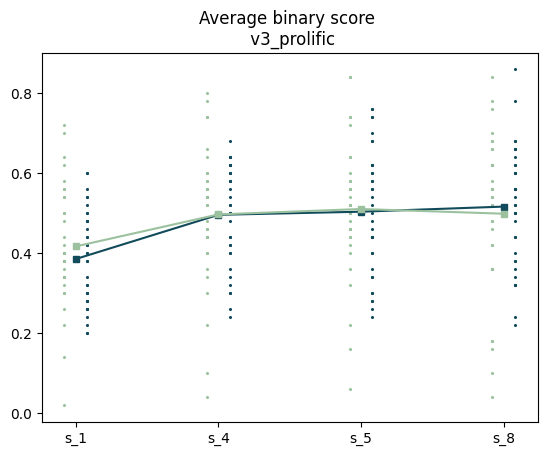

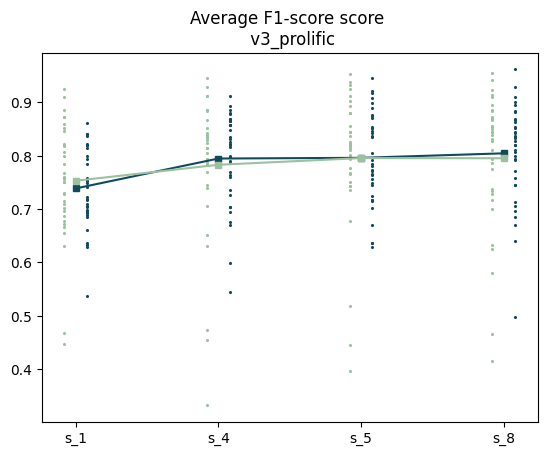

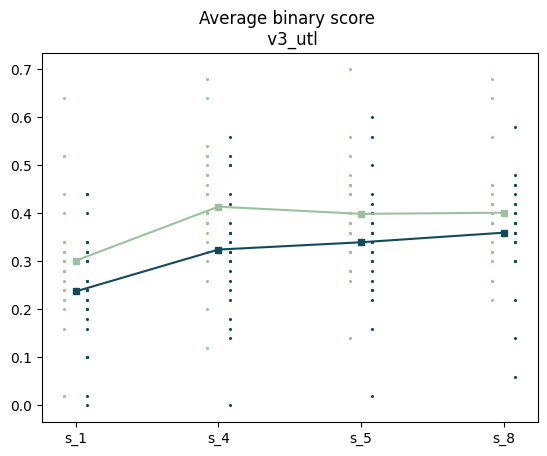

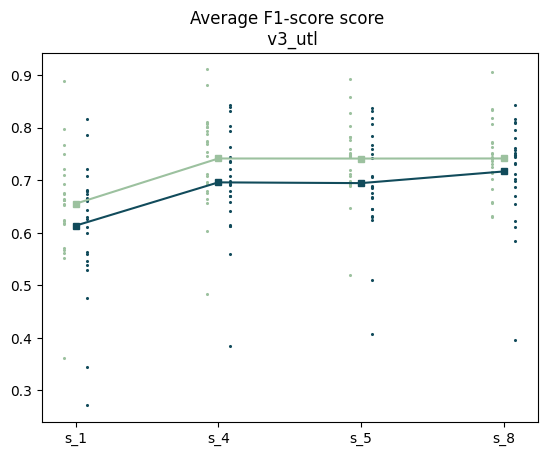

In [30]:
get_mean(v3_prolific_binary, "v3_prolific", "binary")
get_mean(v3_prolific_continuous, "v3_prolific", "F1-score")
get_mean(v3_utl_binary,"v3_utl", "binary")
get_mean(v3_utl_continuous,"v3_utl", "F1-score")

In [4]:
# Assuming X is your data matrix
X = np.vstack(v3_prolific_binary['trajectory'].values)

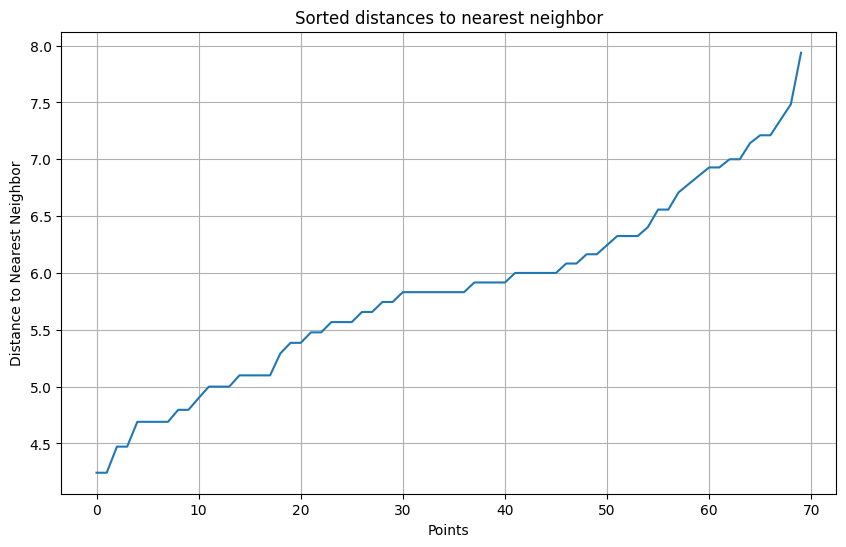

In [100]:
from sklearn.neighbors import NearestNeighbors

# Use NearestNeighbors to find the distance to the nearest neighbor for each point
nearest_neighbors = NearestNeighbors(n_neighbors=2)
nearest_neighbors.fit(X)
distances, indices = nearest_neighbors.kneighbors(X)

# Sort the distances
sorted_distances = np.sort(distances[:, 1])  # Take the second neighbor distance (first is the point itself)

# Plotting the sorted distances
plt.figure(figsize=(10, 6))
plt.plot(sorted_distances)
plt.xlabel('Points')
plt.ylabel('Distance to Nearest Neighbor')
plt.title('Sorted distances to nearest neighbor')
plt.grid(True)
plt.show()

In [53]:
from sklearn.cluster import DBSCAN
for eps_val in [0.01*i for i in range(1, 20)]:
    clustering = DBSCAN(eps=eps_val, min_samples=1, metric='cosine').fit(X)
    labels = clustering.labels_
    print(clustering.labels_, len(set(clustering.labels_)))

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69] 70
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69] 70
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 36 56 57 58 59 60 61 62 63 64 65 66 67 68] 69
[ 0  1  2  3  4  5  6  7  7  8  9 10 11 12 13 14 15 10 16 17 18 19 20 21
 22 23 24 25 26 27 28 29 30 31 32 19  5 33 34 35 36 37 38 39 40 41 42 43
 44 45 46 47 48 49 50 51  5 20 52 53 54 55 56 57 58 59 60 61 18 62] 63
[ 0  1  2  3  4  5  6  7  7  8  5  5  9 10 11 12 13  5  5  5  5  5 14 15
 16 17  5  5 18 19 20 21 22  5 23  5  5 24 25 26 27  5 21  

In [44]:
# Find centroids of clusters
centroids = []
for label in set(labels):
    if label != -1:  # Exclude noise points
        points_in_cluster = X[labels == label]
        centroid = points_in_cluster.mean(axis=0).reshape((3,4,4))
        centroids.append(centroid)
centroids = np.array(centroids)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_77561/611490352.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('gray_r', 5)


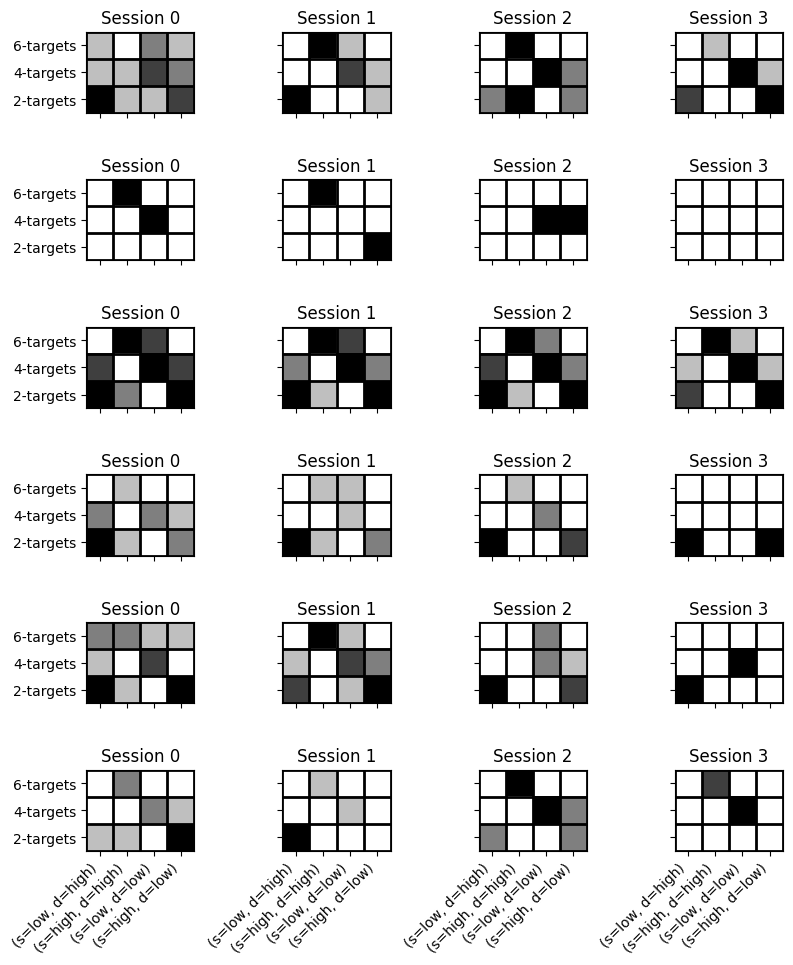

In [57]:
fig, axes = plt.subplots(len(centroids), 4, figsize=(8, 10))  # Adjusted for clarity
x_labels = ['(s=low, d=high)', '(s=high, d=high)', '(s=low, d=low)', '(s=high, d=low)']
y_labels = ['2-targets', '4-targets', '6-targets']
sessions_labels = [f"Session {i}" for i in range(len(centroids))]
cmap = plt.cm.get_cmap('gray_r', 5)

# Loop through the centroids and plot each one
for i, centroid in enumerate(centroids):
    for j in range(4):
        ax = axes[i, j]
        im = ax.imshow(centroid[:, :, j], cmap=cmap, interpolation='nearest', origin='lower')
        ax.set_xticks(np.arange(len(x_labels)))
        ax.set_xticks(np.arange(-.5, len(x_labels), 1), minor=True)
        ax.set_xticklabels(x_labels, rotation=45, ha='right')
        ax.set_yticks(np.arange(len(y_labels)))
        ax.set_yticks(np.arange(-.5, len(y_labels), 1), minor=True)
        ax.set_xticklabels(x_labels if i == len(centroids) - 1 else [], rotation=45, ha='right')
        ax.set_yticklabels(y_labels if j == 0 else [])
        ax.grid(False)  # Turn off the grid unless it's necessary
        ax.title.set_text(sessions_labels[j])
        ax.grid(which='minor', color='black', linestyle='-', linewidth=2)
        ax.tick_params(which='minor', size=0)  # Hide the minor tick marks
# Adjust layout
plt.tight_layout()
fig.savefig("test_DBSCAN.png")